## Importation des bibliothéques


In [6]:
import pandas as pd
from sklearn.linear_model import PassiveAggressiveClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.pipeline import make_pipeline
from wordcloud import WordCloud, STOPWORDS
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import PorterStemmer
import string


### Étape 1 : Charger les données

In [7]:
fake_df = pd.read_csv('Datasets/Fake.csv')
true_df = pd.read_csv('Datasets/True.csv')
tst = pd.read_csv("Datasets/manual_testing.csv")
x_tst = tst["text"]
y_tst = tst["class"]

### Étape 2 : Ajoutez une colonne 'label' pour différencier les fausses et les vraies nouvelles

In [8]:
fake_df['label'] = 0 
true_df['label'] = 1 

### Étape 3 : Combinez les données en un seul DataFrame et mélangez les données

In [9]:
df = pd.concat([fake_df, true_df], ignore_index=True)
df = df.sample(frac=1, random_state=42).reset_index(drop=True)
df

,title,text,subject,date,label
0,Ben Stein Calls Out 9th Circuit Court: Committ...,"21st Century Wire says Ben Stein, reputable pr...",US_News,"February 13, 2017",0
1,Trump drops Steve Bannon from National Securit...,WASHINGTON (Reuters) - U.S. President Donald T...,politicsNews,"April 5, 2017",1
2,Puerto Rico expects U.S. to lift Jones Act shi...,(Reuters) - Puerto Rico Governor Ricardo Rosse...,politicsNews,"September 27, 2017",1
3,OOPS: Trump Just Accidentally Confirmed He Le...,"On Monday, Donald Trump once again embarrassed...",News,"May 22, 2017",0
4,Donald Trump heads for Scotland to reopen a go...,"GLASGOW, Scotland (Reuters) - Most U.S. presid...",politicsNews,"June 24, 2016",1
...,...,...,...,...,...
44893,UNREAL! CBS’S TED KOPPEL Tells Sean Hannity He...,,politics,"Mar 27, 2017",0
44894,PM May seeks to ease Japan's Brexit fears duri...,LONDON/TOKYO (Reuters) - British Prime Ministe...,worldnews,"August 29, 2017",1
44895,Merkel: Difficult German coalition talks can r...,BERLIN (Reuters) - Chancellor Angela Merkel sa...,worldnews,"November 16, 2017",1
44896,Trump Stole An Idea From North Korean Propaga...,Jesus f*cking Christ our President* is a moron...,News,"July 14, 2017",0


### Supprimer les colonnes non nécessaires


In [10]:
df = df.drop(columns=["title", "subject", "date"])
df["text"]

0        21st Century Wire says Ben Stein, reputable pr...
1        WASHINGTON (Reuters) - U.S. President Donald T...
2        (Reuters) - Puerto Rico Governor Ricardo Rosse...
3        On Monday, Donald Trump once again embarrassed...
4        GLASGOW, Scotland (Reuters) - Most U.S. presid...
                               ...                        
44893                                                     
44894    LONDON/TOKYO (Reuters) - British Prime Ministe...
44895    BERLIN (Reuters) - Chancellor Angela Merkel sa...
44896    Jesus f*cking Christ our President* is a moron...
44897    IF SHE S NOT TOAST NOW THEN WE RE IN BIGGER TR...
Name: text, Length: 44898, dtype: object

### Fonction pour obtenir les mots les plus fréquents

In [11]:
from collections import Counter
import nltk

# Télécharger les stopwords et punkt
nltk.download('stopwords')
nltk.download('punkt')

def get_most_common_words(texts, num_words=10):
    all_words = []
    for text in texts:
        all_words.extend(nltk.word_tokenize(text.lower()))
    stop_words = set(nltk.corpus.stopwords.words('english'))
    words = [word for word in all_words if word.isalpha() and word not in stop_words]
    word_counts = Counter(words)
    return word_counts.most_common(num_words)

# Obtenir les mots les plus fréquents dans les vrais et faux articles
real_words = get_most_common_words(true_df['text'])
fake_words = get_most_common_words(fake_df['text'])

print('Real News:', real_words)
print('Fake News:', fake_words)

[nltk_data] Error loading stopwords: <urlopen error [Errno 11001]
[nltk_data]     getaddrinfo failed>
[nltk_data] Error loading punkt: <urlopen error [Errno 11001]
[nltk_data]     getaddrinfo failed>


Real News: [('said', 99037), ('trump', 54249), ('would', 31526), ('reuters', 28412), ('president', 26397), ('state', 19728), ('government', 18288), ('new', 16784), ('house', 16519), ('states', 16515)]
Fake News: [('trump', 74241), ('said', 31149), ('people', 26015), ('president', 25772), ('would', 23461), ('one', 22995), ('clinton', 18085), ('obama', 17920), ('like', 17660), ('donald', 17235)]


In [12]:
stop_words = set(stopwords.words('english'))
stemmer = PorterStemmer()

# Fonction de prétraitement du texte
def preprocess_text(text):
    # Mettre le texte en minuscule
    text = text.lower()

    # Retirer la ponctuation et les chiffres
    text = text.translate(str.maketrans('', '', string.punctuation + string.digits))

    # Tokenizer le texte
    words = word_tokenize(text)

    # Retirer les stopwords
    words = [word for word in words if word not in stop_words]

    # Raciniser les mots
    words = [stemmer.stem(word) for word in words]

    # Rejoindre les mots en une chaîne
    text = ' '.join(words)

    return text

# Prétraiter les textes
true_processed_texts = true_df['text'].apply(preprocess_text)
fake_processed_texts = fake_df['text'].apply(preprocess_text)

true_df ["text"] = true_processed_texts
fake_df["text"] = fake_processed_texts


### Générer des nuages de mots

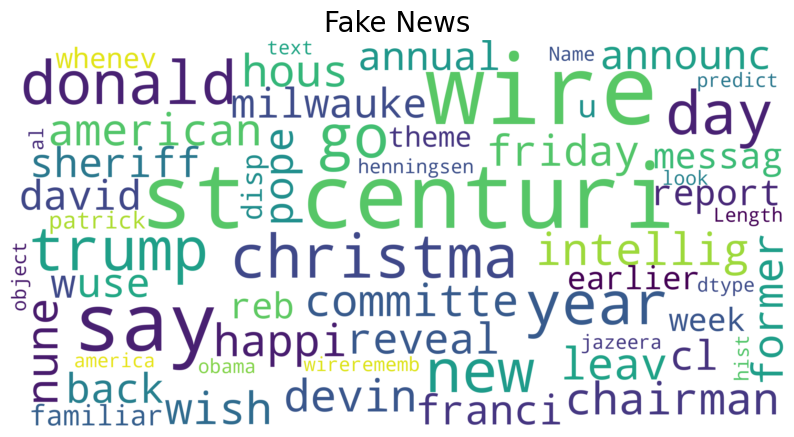

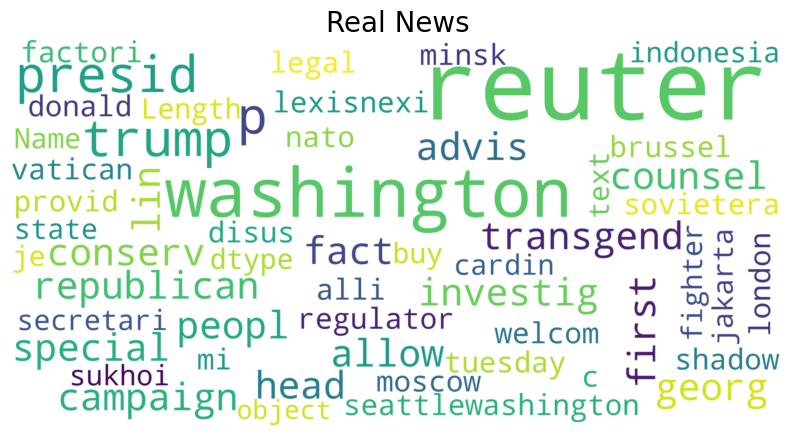

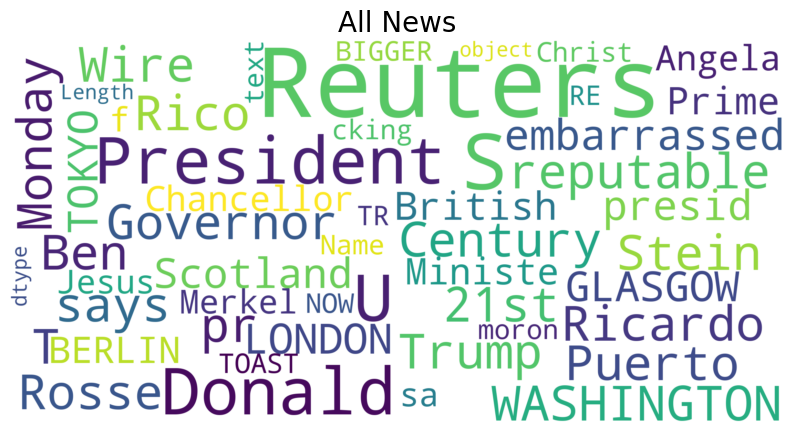

In [13]:
def generate_wordcloud(text, title):
    stopwords = set(STOPWORDS)
    wordcloud = WordCloud(
        width=800, height=400,
        background_color='white',
        stopwords=stopwords,
        max_words=200,
        max_font_size=100, 
        scale=3,
        random_state=42
    ).generate(str(text))
    
    plt.figure(figsize=(10, 7))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.title(title, fontsize=20)
    plt.axis('off')
    plt.show()

generate_wordcloud(fake_df["text"], 'Fake News')

generate_wordcloud(true_df["text"], 'Real News')

generate_wordcloud(df["text"], "All News")

### Séparer les données en ensembles d'entraînement et de test

In [14]:
X = df['text']
y = df['label']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

### Creation des Modeles

In [15]:

model = make_pipeline(TfidfVectorizer(stop_words='english', max_df=0.7), PassiveAggressiveClassifier(max_iter=100, random_state=42))
modelDT = make_pipeline(TfidfVectorizer(stop_words='english', max_df=0.7), DecisionTreeClassifier(random_state=42))
modelLR = make_pipeline(TfidfVectorizer(stop_words='english', max_df=0.7), LogisticRegression(max_iter=100, random_state=42))
modelRF = make_pipeline(TfidfVectorizer(stop_words='english', max_df=0.7), RandomForestClassifier(n_estimators=100, random_state=42))


### L'entrainement des Modeles

In [16]:
model.fit(X_train, y_train)
modelLR.fit(X_train, y_train)
modelRF.fit(X_train, y_train)
modelDT.fit(X_train, y_train)

Pipeline(steps=[('tfidfvectorizer',
                 TfidfVectorizer(max_df=0.7, stop_words='english')),
                ('decisiontreeclassifier',
                 DecisionTreeClassifier(random_state=42))])

### Faire des prédictions

In [17]:
y_pred = model.predict(X_test)
y_predLR = modelLR.predict(X_test)
y_predRF = modelRF.predict(X_test)
y_predDT = modelDT.predict(X_test)


### Calculer les scores de précision pour les differentes modeles

C:\Users\Dell\AppData\Local\Temp\ipykernel_8940\1037122616.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(acc.keys()), y=list(acc.values()), palette= "dark")
c:\Users\Dell\AppData\Local\Programs\Python\Python312\Lib\site-packages\seaborn\_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
c:\Users\Dell\AppData\Local\Programs\Python\Python312\Lib\site-packages\seaborn\_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
c:\

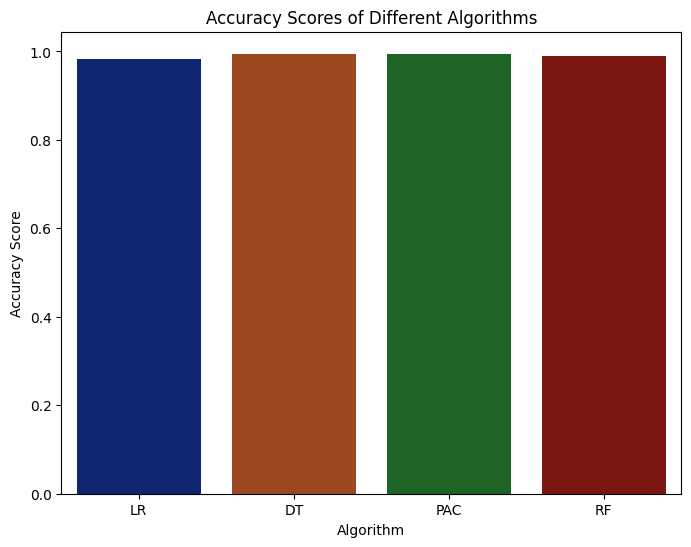

In [18]:
acc = {
    "LR": accuracy_score(y_predLR, y_test),
    "DT": accuracy_score(y_predDT, y_test),
    "PAC": accuracy_score(y_pred, y_test),
    "RF": accuracy_score(y_predRF, y_test)
}
color=["red", "purple", "green", "blue"]
plt.figure(figsize=(8, 6))
sns.barplot(x=list(acc.keys()), y=list(acc.values()), palette= "dark")
plt.xlabel('Algorithm')
plt.ylabel('Accuracy Score')
plt.title('Accuracy Scores of Different Algorithms')
plt.show()

### Calculer et afficher les métriques de performance

[[4618   92]
 [  66 4204]]


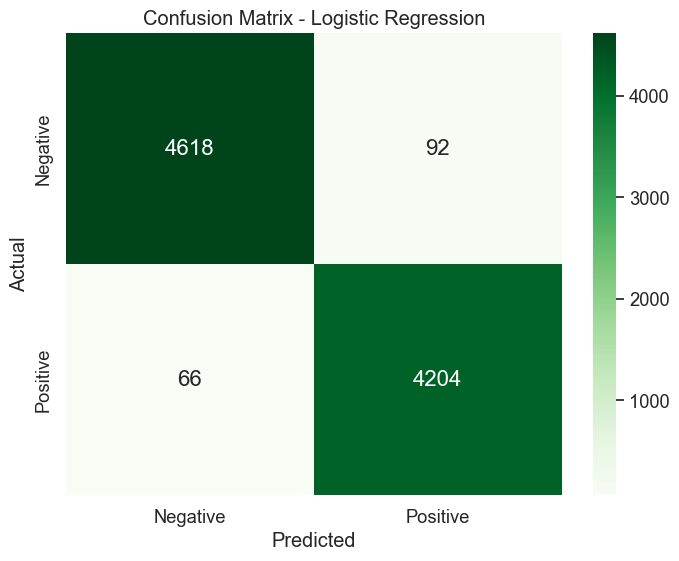

[[4695   15]
 [  32 4238]]


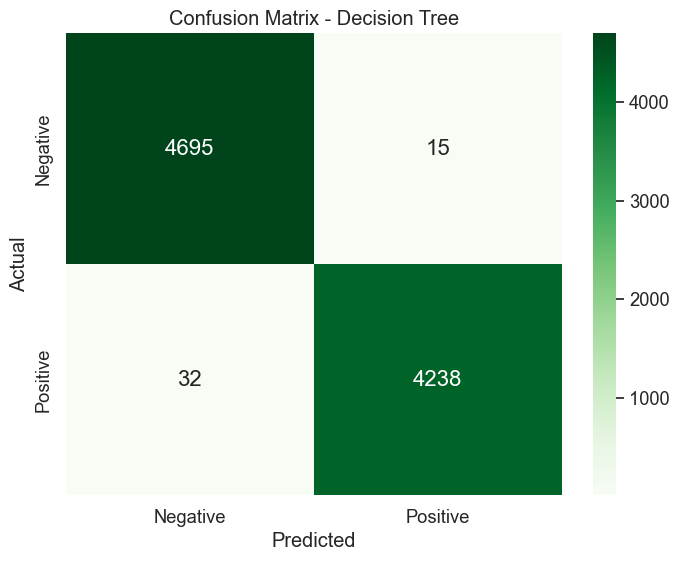

[[4681   29]
 [  29 4241]]


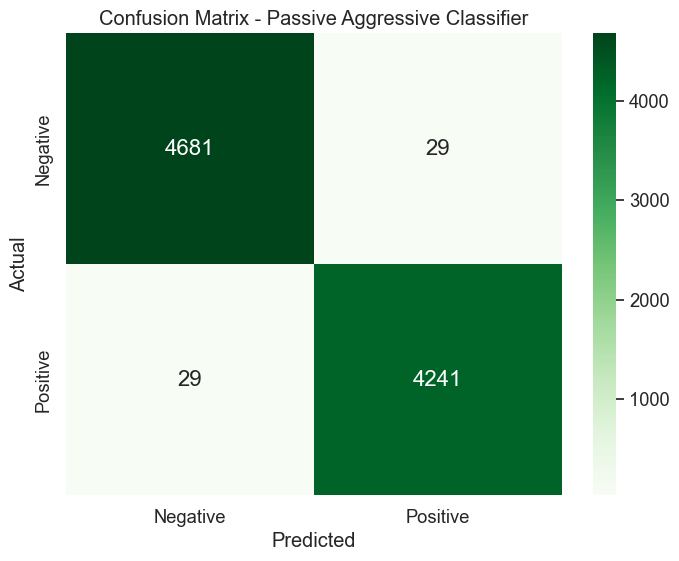

[[4656   54]
 [  40 4230]]


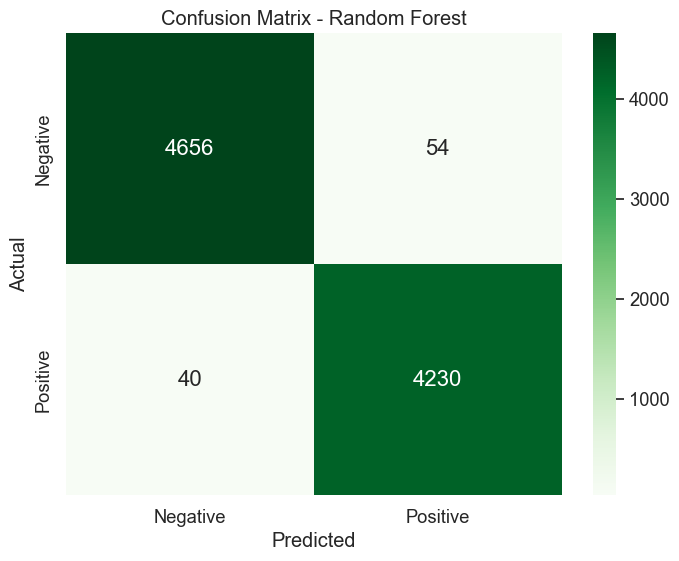

In [19]:
mod = {
    'Logistic Regression': y_predLR,
    'Decision Tree': y_predDT,
    'Passive Aggressive Classifier': y_pred,
    'Random Forest': y_predRF
}

for model, y_pred in mod.items():
    cm = confusion_matrix(y_test, y_pred)
    print(cm)
    plt.figure(figsize=(8, 6))
    sns.set(font_scale=1.2) 
    sns.heatmap(cm, annot=True, fmt='g', cmap='Greens', annot_kws={"size": 16}, 
                xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title(f'Confusion Matrix - {model}')
    plt.show()

### L'evaluation des Modeles

In [20]:
mod = {
    'Logistic Regression': y_predLR,
    'Decision Tree': y_predDT,
    'Passive Aggressive Classifier': y_pred,
    'Random Forest': y_predRF
}

for model, y_pred in mod.items():
    accuracy = accuracy_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    pres = precision_score(y_test, y_pred, pos_label=1)
    
    print(f"Pour {model}: ")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {pres:.4f}")
    print(f"recall-score: {recall:.4f}")
    print(f"f1-score: {f1:.4f}")
    print("*********************************************")
  

Pour Logistic Regression: 
Accuracy: 0.9824
Precision: 0.9786
recall-score: 0.9845
f1-score: 0.9816
*********************************************
Pour Decision Tree: 
Accuracy: 0.9948
Precision: 0.9965
recall-score: 0.9925
f1-score: 0.9945
*********************************************
Pour Passive Aggressive Classifier: 
Accuracy: 0.9895
Precision: 0.9874
recall-score: 0.9906
f1-score: 0.9890
*********************************************
Pour Random Forest: 
Accuracy: 0.9895
Precision: 0.9874
recall-score: 0.9906
f1-score: 0.9890
*********************************************
